# Exploratory Data Analysis (EDA)

## Overview
This notebook focuses on exploring and understanding the df dataset before building a machine learning model to predict house prices.

## Objectives
- Understand the structure and characteristics of the dataset.
- Identify missing values and potential data quality issues.
- Analyze the distribution of house prices and relevant features.
- Explore relationships and correlations between features.
- Identify patterns, outliers, and insights that may influence model development.

## Workflow
1. Inspect the dataset structure and summary statistics.
2. Examine missing values and data quality.
3. Analyze numerical and categorical features.
4. Investigate feature relationships and correlations.
5. Summarize key findings to guide the preprocessing and modeling stages.

## Expected Outcome
Gain a clear understanding of the dataset and identify the main considerations for data preprocessing and machine learning.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
import warnings
warnings.filterwarnings('ignore')

## 2. Load the Dataset

In [2]:
df = pd.read_csv('../data/raw/housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Initial Data Inspection


- Check the number of rows and columns.
- Inspect column names and data types.
- Review summary information about the dataset.

In [3]:
df.shape

(20640, 10)

In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [6]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [7]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

### Initial Inspection Summary

The dataset contains 20,640 rows and 10 columns, including numerical and categorical features. The initial inspection identified 207 missing values in total_bedrooms. The target variable for prediction is median_house_value.

## 4.Target Variable Distribution

In this section, we analyze the distribution of `median_house_value` to understand the range, spread, and distribution of house values before building a predictive model.

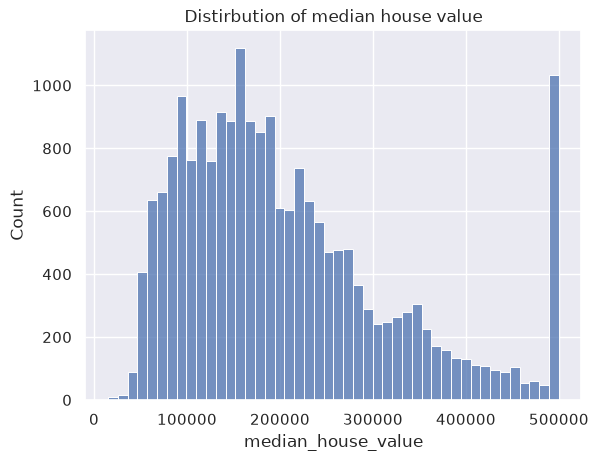

In [8]:
fig,ax = plt.subplots()

sns.histplot(
    data=df,
    x='median_house_value',

)

ax.set_title('Distirbution of median house value')
fig.show()

**Key Findings**

The target variable, `median_house_value`, has a right-skewed distribution, with most observations concentrated at lower price ranges. A prominent spike appears near the upper price limit of 500,001, suggesting that house values may be capped in the dataset. This limitation may affect the model's ability to predict higher house prices accurately.

## Correlation Analysis

In this section, we examine the correlations between numerical features to identify relationships that may be useful for predicting `median_house_value`.

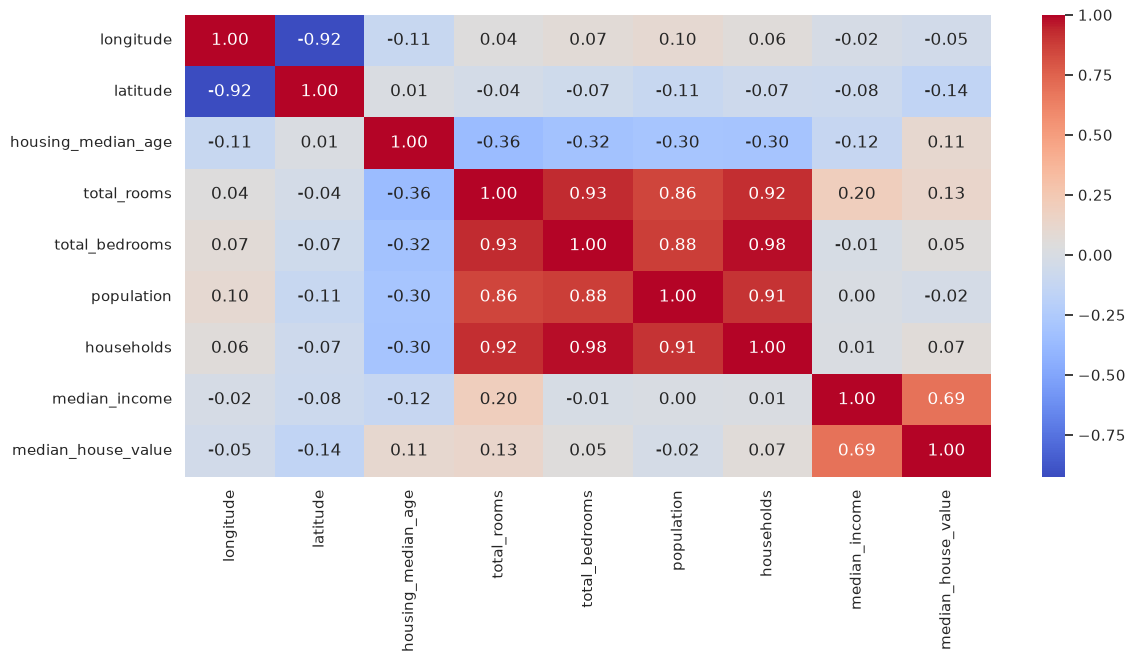

In [9]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13,6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

fig.show()

**Key Findings**

`median_income` has the strongest positive linear correlation with `median_house_value` (0.688). Several other numerical features show relatively weak linear correlations with the target. Strong correlations also exist between some predictors, particularly `total_rooms` and `total_bedrooms` (0.930). These relationships provide useful insights for feature analysis, although correlation alone does not determine a feature's predictive value.

## Relationship Between Median Income and House Value

In this section, we visualize the relationship between `median_income` and `median_house_value` using a scatter plot to identify patterns, non-linear relationships, and potential price limitations in the dataset.

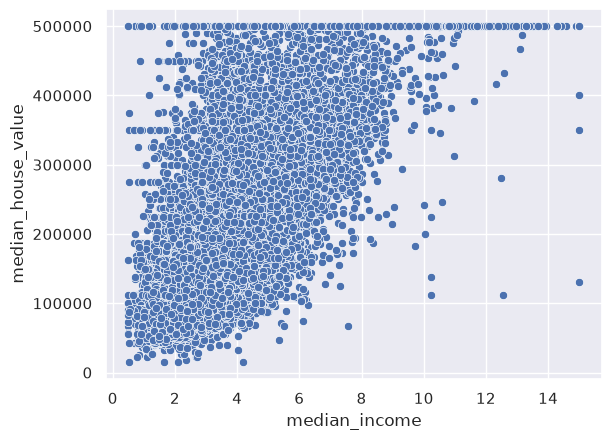

In [10]:
fig, ax = plt.subplots()

sns.scatterplot(
    data=df,
    x='median_income',
    y='median_house_value'
)

fig.show()

**Key Findings**

The scatter plot shows a positive relationship between `median_income` and `median_house_value`. However, the relationship is not perfectly linear, and house values vary considerably at similar income levels. A prominent horizontal band at the upper price limit of 500,001 suggests that the target values are capped, which may limit prediction accuracy for higher-priced houses.

## Geographical Data Analysis

In this section, we explore the geographical distribution of housing data using `longitude` and `latitude`. We visualize the locations of housing districts and examine how their median house values vary across different regions.

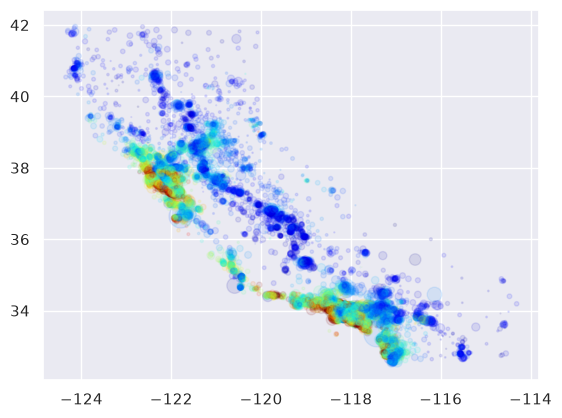

In [11]:
fig, ax = plt.subplots()

ax.scatter(
    data=df,
    x='longitude',
    y='latitude', 
    alpha=0.1,
    s=df['population']/100,
    c='median_house_value',cmap=plt.get_cmap('jet')
)

fig.show()

**Key Findings**

The geographical scatter plot reveals clear spatial patterns in median house values. Higher-value housing districts appear concentrated in certain coastal and urban areas, while other regions show generally lower values. This suggests that geographical location may be an important feature for predicting house prices.

## Feature Engineering: Creating New Attributes

In this section, we create new features by combining existing attributes to capture more meaningful relationships within the housing data. These features include rooms per household, bedrooms per room, and population per household.

We then examine their correlations with `median_house_value` to evaluate their potential usefulness for predicting house prices.

In [12]:
df["rooms_per_household"] = df["total_rooms"]/df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"]/df["total_rooms"]
df["population_per_household"]=df["population"]/df["households"]

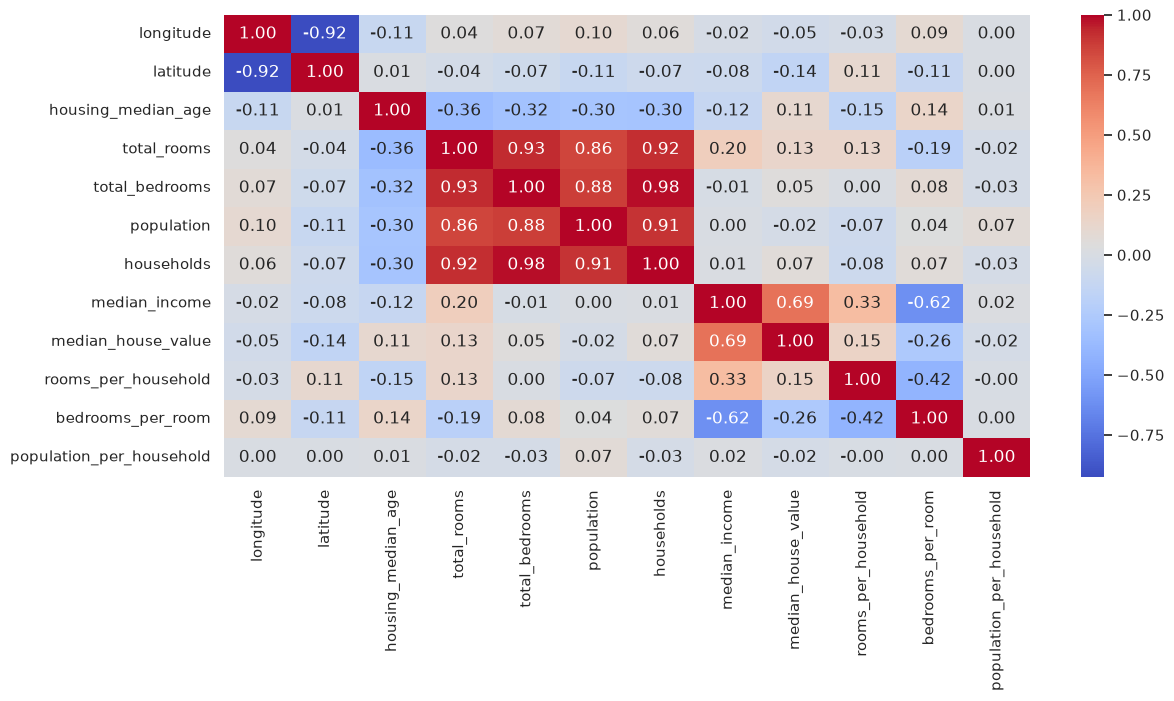

In [13]:
corr = df.corr(numeric_only=True)

corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13,6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

fig.show()

**Key Findings**

`median_income` remains the feature most strongly correlated with `median_house_value` (0.69). Among the newly engineered features, `bedrooms_per_room` shows a negative correlation (-0.26), while `rooms_per_household` has a weak positive correlation (0.15). `population_per_household` shows almost no linear correlation with the target. These results suggest that some feature combinations may provide additional predictive information.

# Data Preprocessing

In this section, we prepare the housing dataset for machine learning by splitting the data into training and test sets, handling missing values, transforming categorical and numerical features, and applying feature engineering where appropriate.

All preprocessing steps will be fitted using the training data to prevent data leakage and ensure a reliable evaluation of the final model.

## Train-Test Split

Before preprocessing the data, we split the dataset into training and test sets. The training set will be used to build the machine learning model, while the test set will be reserved for evaluating its performance on unseen data.

Separating the test set early helps prevent data leakage and provides a more reliable estimate of the model's generalization performance.

In [14]:
from sklearn.model_selection import train_test_split

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

## Data Cleaning

The `total_bedrooms` column contains 207 missing values. Since this is a numerical feature, we use median imputation to handle the missing values.

The imputer is fitted only on the training data to prevent data leakage. The same fitted imputer is then used to transform both the training and test sets, ensuring consistent preprocessing.

In [16]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train_num = X_train.drop('ocean_proximity', axis=1)
X_test_num = X_test.drop('ocean_proximity', axis=1)


imputer.fit(X_train_num)

X_train_num = imputer.transform(X_train_num)
X_test_num = imputer.transform(X_test_num)


X_train_num_encoded = pd.DataFrame(
    X_train_num,
    columns=imputer.feature_names_in_,
    index=X_train.index
)

X_test_num_encoded = pd.DataFrame(
    X_test_num,
    columns=imputer.feature_names_in_,
    index=X_test.index
)

print("train features \n",X_train_num_encoded.isnull().sum())
print("_______________________________")
print("train features \n",X_test_num_encoded.isnull().sum())


train features 
 longitude                   0
latitude                    0
housing_median_age          0
total_rooms                 0
total_bedrooms              0
population                  0
households                  0
median_income               0
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
dtype: int64
_______________________________
train features 
 longitude                   0
latitude                    0
housing_median_age          0
total_rooms                 0
total_bedrooms              0
population                  0
households                  0
median_income               0
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
dtype: int64


## Handling Text and Categorical Attributes

The `ocean_proximity` column contains categorical text values rather than numerical data. Most machine learning algorithms require numerical inputs, so we need to convert these categories into numerical representations.

We will use one-hot encoding to represent each category as a separate binary feature.

In [17]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()

X_train_cat = X_train[["ocean_proximity"]]
X_test_cat = X_test[["ocean_proximity"]]

X_train_cat = cat_encoder.fit_transform(X_train_cat)
X_test_cat = cat_encoder.transform(X_test_cat)

In [18]:
X_train_cat_encoded = pd.DataFrame(
    X_train_cat.toarray(),
    columns=cat_encoder.get_feature_names_out(),
    index=X_train.index
)

X_test_cat_encoded = pd.DataFrame(
    X_test_cat.toarray(),
    columns=cat_encoder.get_feature_names_out(),
    index=X_test.index
)


## Combining Transformed Features

In this step, we combine the numerical features with the one-hot encoded categorical features to create the final training and test datasets.

We ensure that both datasets have the same feature columns and that the preprocessing steps are applied consistently.

In [19]:
X_train_encoded = pd.concat([X_train_num_encoded, X_train_cat_encoded], axis=1)
X_test_encoded = pd.concat([X_test_num_encoded, X_test_cat_encoded], axis=1)

In [20]:
X_train_encoded

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,-117.22,32.75,34.0,6001.0,1111.0,2654.0,1072.0,4.5878,5.597948,0.185136,2.475746,0.0,0.0,0.0,0.0,1.0
8267,-117.03,32.69,10.0,901.0,163.0,698.0,167.0,4.6648,5.395210,0.180910,4.179641,0.0,0.0,0.0,0.0,1.0
17445,-122.27,37.74,28.0,6909.0,1554.0,2974.0,1484.0,3.6875,4.655660,0.224924,2.004043,0.0,0.0,0.0,1.0,0.0
14265,-121.82,37.25,25.0,4021.0,634.0,2178.0,650.0,5.1663,6.186154,0.157672,3.350769,1.0,0.0,0.0,0.0,0.0
2271,-115.98,33.32,8.0,240.0,46.0,63.0,24.0,1.4688,10.000000,0.191667,2.625000,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,-122.37,37.94,49.0,969.0,229.0,599.0,195.0,1.3167,4.969231,0.236326,3.071795,0.0,0.0,0.0,1.0,0.0
11964,-118.38,33.89,35.0,1778.0,330.0,732.0,312.0,6.5745,5.698718,0.185602,2.346154,1.0,0.0,0.0,0.0,0.0
5390,-119.33,36.28,16.0,2624.0,527.0,1077.0,520.0,2.1250,5.046154,0.200838,2.071154,0.0,1.0,0.0,0.0,0.0
860,-117.19,34.08,22.0,2467.0,555.0,1567.0,494.0,2.6536,4.993927,0.224970,3.172065,0.0,1.0,0.0,0.0,0.0
